# 3. CPTAC validation results

Consolidated replacement for `3. results_tmt.ipynb`, `3. results_labelfree.ipynb`, and `3. results_itraq.ipynb`.

This notebook checks the saved best-model result files, evaluates the same coefficient-dictionary models on TMT, LabelFree, and iTRAQ validation data, compares all tissues versus a filtered-tissue view, and produces compact summary plots.

In [1]:
from pathlib import Path
import sys

NOTEBOOK_DIR = Path.cwd()
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

import src.utils_val as uv
from src.utils_val import (
    load_best_result_tables,
    load_batch_result_tables,
    compare_model_result_tables,
    evaluate_cptac_validation_datasets,
    summarize_cptac_results,
    plot_cptac_summary,
    plot_cptac_metric_distributions,
    plot_cptac_tissue_mse,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 180, "axes.titleweight": "bold"})

## 1. Configuration

Paths match the original notebooks. `results_val` holds the trained coefficient models; `val_data` holds normalized validation matrices generated by notebook 2.

In [2]:
RESULTS_DIR = Path("../results_val")
VAL_DATA_DIR = Path("../val_data")
OUTPUT_DIR = Path("../results_val/plots_cptac_unified")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

DATASET_CONFIGS = {
    "TMT": {
        "rna_path": VAL_DATA_DIR / "TMT_transcriptomics.joblib",
        "prot_path": VAL_DATA_DIR / "TMT_proteomics.joblib",
    },
    "LabelFree": {
        "rna_path": VAL_DATA_DIR / "LabelFree_transcriptomics.joblib",
        "prot_path": VAL_DATA_DIR / "LabelFree_proteomics.joblib",
    },
    "iTRAQ": {
        "rna_path": VAL_DATA_DIR / "iTRAQ_transcriptomics.joblib",
        "prot_path": VAL_DATA_DIR / "iTRAQ_proteomics.joblib",
    },
}

# Same filtered-tissue list used in the original split notebooks.
EXCLUDED_TISSUES = ["RENAL_2019", "HEADNECK_2021", "PANCREA2021"]

# Original notebook skipped models with missing RNA features. Keep that behavior here.
IMPUTE_MISSING_FEATURES = False

print("Results directory:", RESULTS_DIR.resolve())
print("Validation data directory:", VAL_DATA_DIR.resolve())

Results directory: C:\Users\hp\Desktop\new_pRNA\results_val
Validation data directory: C:\Users\hp\Desktop\new_pRNA\val_data


## 2. Best-model and batch-file consistency check

In [3]:
best_models, best_files = load_best_result_tables(RESULTS_DIR)
batch_models, batch_files = load_batch_result_tables(RESULTS_DIR)
comparison = compare_model_result_tables(best_models, batch_models)

print(f"Best-model files: {len(best_files)}")
print(f"Batch files:      {len(batch_files)}")
print(f"Best rows:        {len(best_models):,}")
print(f"Batch rows:       {len(batch_models):,}")
display(pd.DataFrame([comparison]).drop(columns=["missing_in_batch", "missing_in_best"], errors="ignore"))

if comparison.get("missing_in_batch"):
    print("Proteins in best files but not batch files:", comparison["missing_in_batch"][:10])
if comparison.get("missing_in_best"):
    print("Proteins in batch files but not best files:", comparison["missing_in_best"][:10])

display(best_models.head())

Best-model files: 0
Batch files:      0
Best rows:        0
Batch rows:       0


,can_compare,best_rows,batch_rows,message
0,False,0,0,One or both result tables are empty.


""


## 3. Evaluate all CPTAC validation datasets

Each dataset is evaluated twice: first with all tissues, then after dropping the three known high-error tissue groups used in the original notebooks.

In [4]:
cptac_results = evaluate_cptac_validation_datasets(
    DATASET_CONFIGS,
    best_models,
    excluded_tissues=EXCLUDED_TISSUES,
    impute_missing_features=IMPUTE_MISSING_FEATURES,
)

summary_df = summarize_cptac_results(cptac_results)
print("Summary rows:", len(summary_df))
display(summary_df.round(4))


Dataset: TMT


## 4. Feature coverage and zero inflation checks

In [ ]:
coverage_rows = []
zero_rows = []
for (dataset, scope), bundle in cptac_results.items():
    cov = bundle["coverage_df"].copy()
    if len(cov):
        cov["Dataset"] = dataset
        cov["Scope"] = scope
        coverage_rows.append(cov)
    zeros = bundle["zero_stats"].copy()
    if len(zeros):
        zeros["Dataset"] = dataset
        zeros["Scope"] = scope
        zero_rows.append(zeros)

coverage_df = pd.concat(coverage_rows, ignore_index=True) if coverage_rows else pd.DataFrame()
zero_stats_df = pd.concat(zero_rows, ignore_index=True) if zero_rows else pd.DataFrame()

if len(coverage_df):
    coverage_summary = (
        coverage_df.groupby(["Dataset", "Scope"], as_index=False)
        .agg(
            models=("Protein", "nunique"),
            median_missing_fraction=("missing_fraction", "median"),
            max_missing_fraction=("missing_fraction", "max"),
        )
    )
    display(coverage_summary.round(4))

if len(zero_stats_df):
    print("Highest RNA zero percentages by dataset/scope")
    display(
        zero_stats_df.sort_values("percent_zeros", ascending=False)
        .groupby(["Dataset", "Scope"], as_index=False)
        .head(5)
        .round(3)
    )

,Dataset,Scope,models,median_missing_fraction,max_missing_fraction
0,LabelFree,all_tissues,1809,0.0025,0.0201
1,LabelFree,filtered_tissues,1809,0.0025,0.0201
2,TMT,all_tissues,1809,0.0025,0.0201
3,TMT,filtered_tissues,1809,0.0025,0.0201
4,iTRAQ,all_tissues,1809,0.0025,0.0201
5,iTRAQ,filtered_tissues,1809,0.0025,0.0201


Highest RNA zero percentages by dataset/scope


,Tissue,percent_zeros,samples,Dataset,Scope
0,BRAIN_2021,0.0,108,TMT,all_tissues
19,LUNG_VAL,0.0,211,TMT,filtered_tissues
21,BRAIN,0.0,71,LabelFree,all_tissues
22,COLON,0.0,86,LabelFree,all_tissues
23,LIVER,0.0,62,LabelFree,all_tissues
24,LUNG,0.0,76,LabelFree,all_tissues
25,PROSTATE,0.0,65,LabelFree,all_tissues
26,BRAIN,0.0,71,LabelFree,filtered_tissues
27,COLON,0.0,86,LabelFree,filtered_tissues
28,LIVER,0.0,62,LabelFree,filtered_tissues


## 5. Compact performance plots

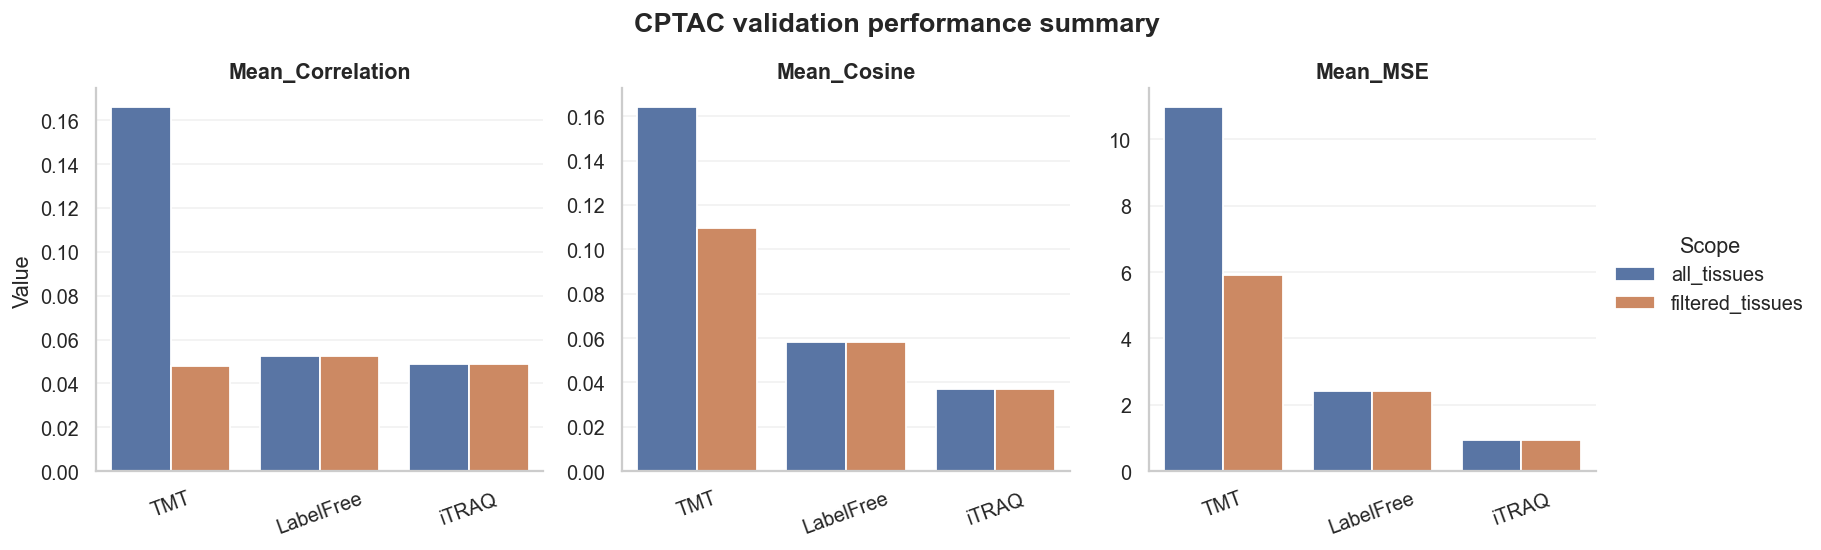

In [ ]:
fig = plot_cptac_summary(summary_df)
if fig is not None:
    fig.savefig(OUTPUT_DIR / "cptac_summary.png", bbox_inches="tight")

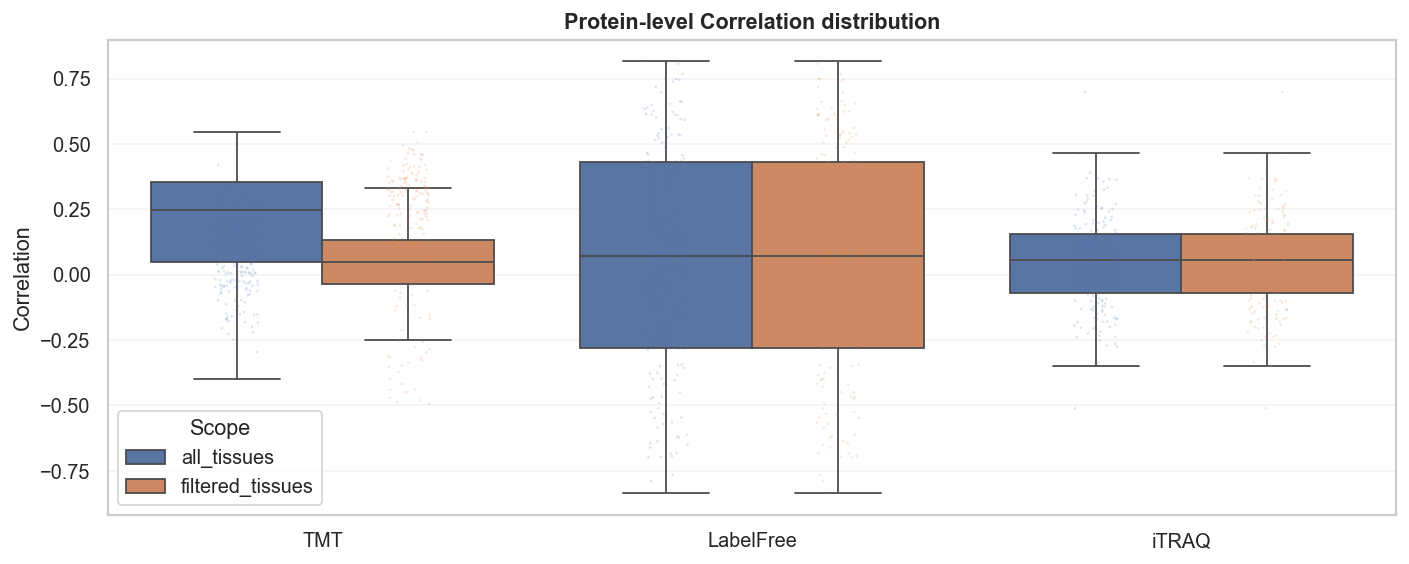

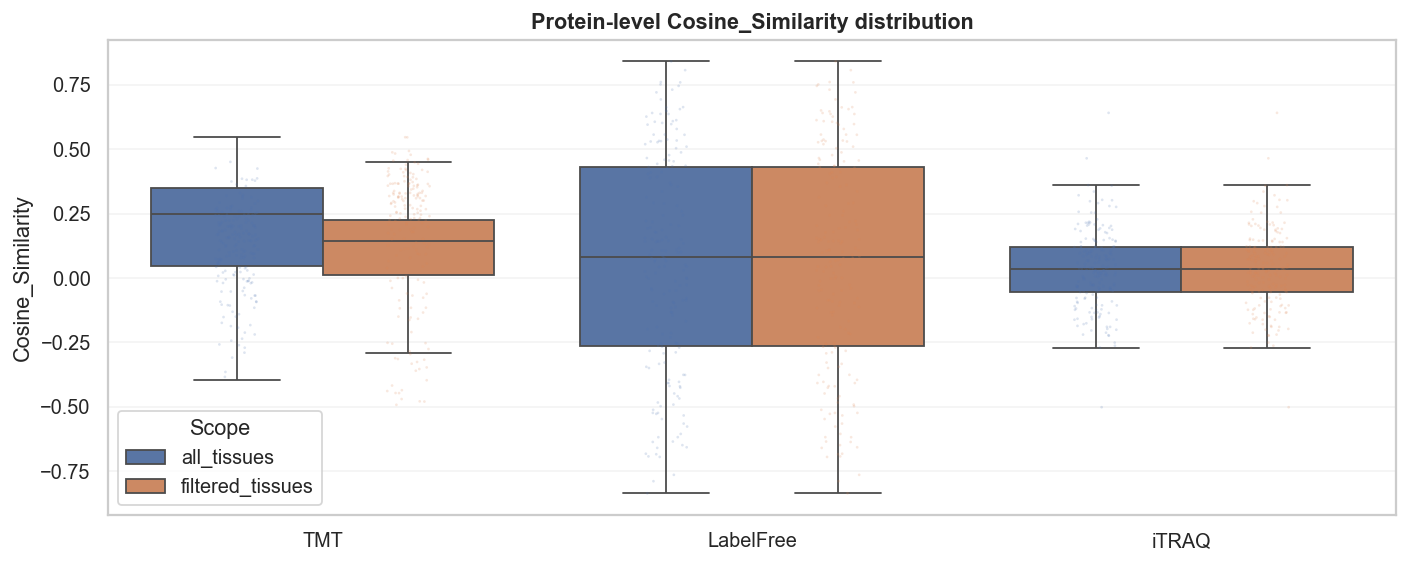

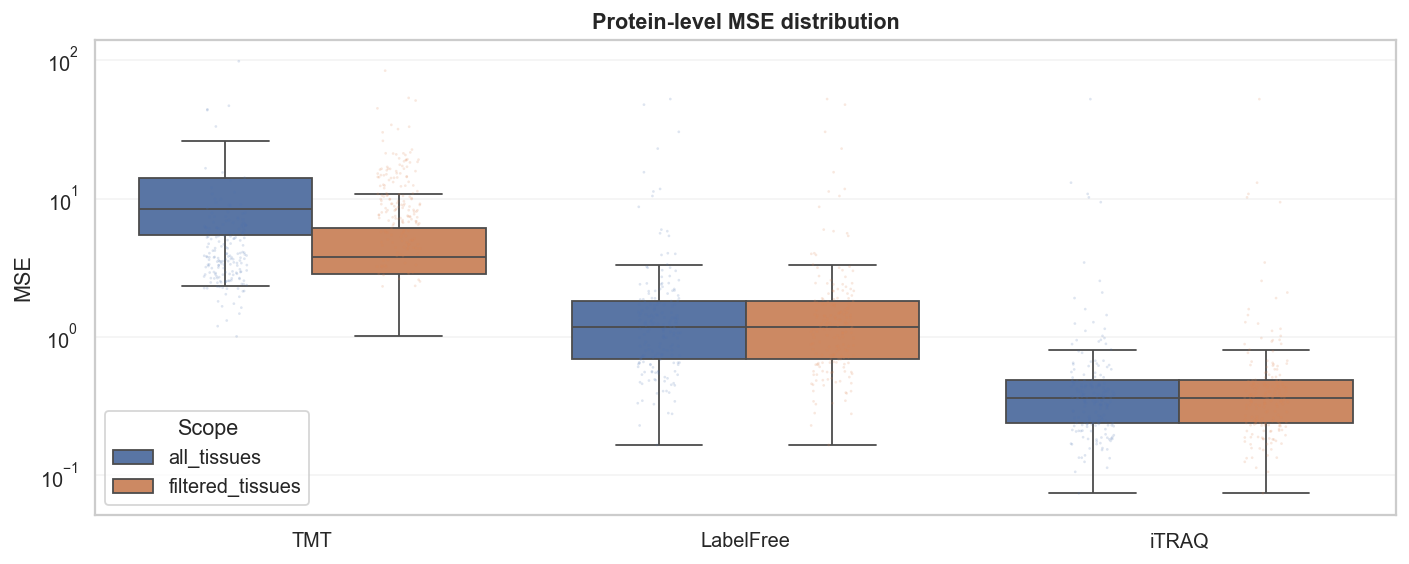

In [ ]:
long_results = []
for (dataset, scope), bundle in cptac_results.items():
    df = bundle["results_df"].copy()
    if len(df):
        df["Dataset"] = dataset
        df["Scope"] = scope
        long_results.append(df)

long_results_df = pd.concat(long_results, ignore_index=True) if long_results else pd.DataFrame()
plot_cptac_metric_distributions(long_results_df)

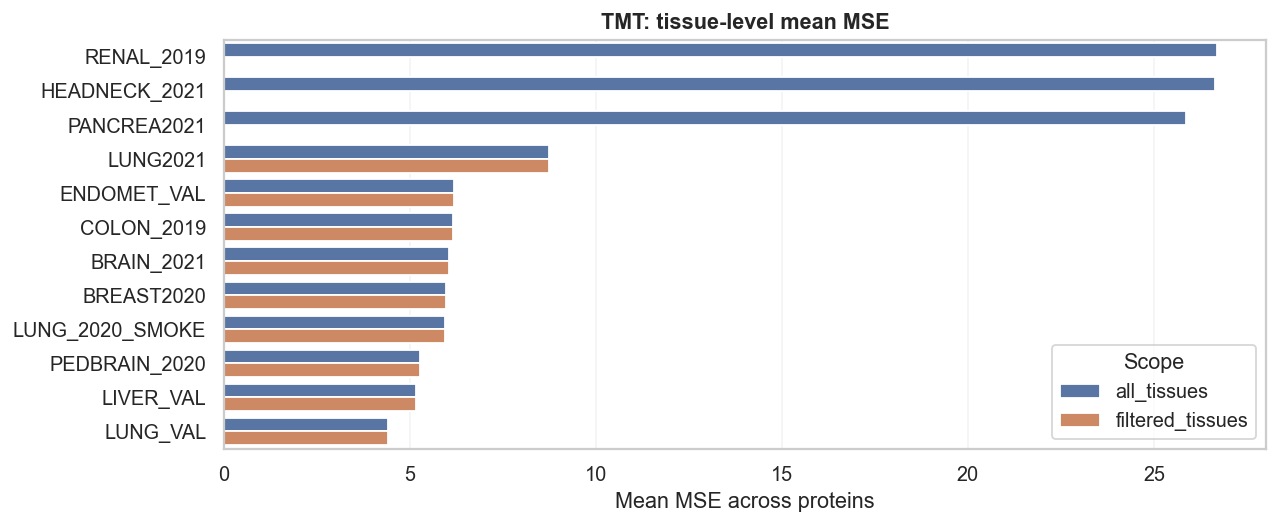

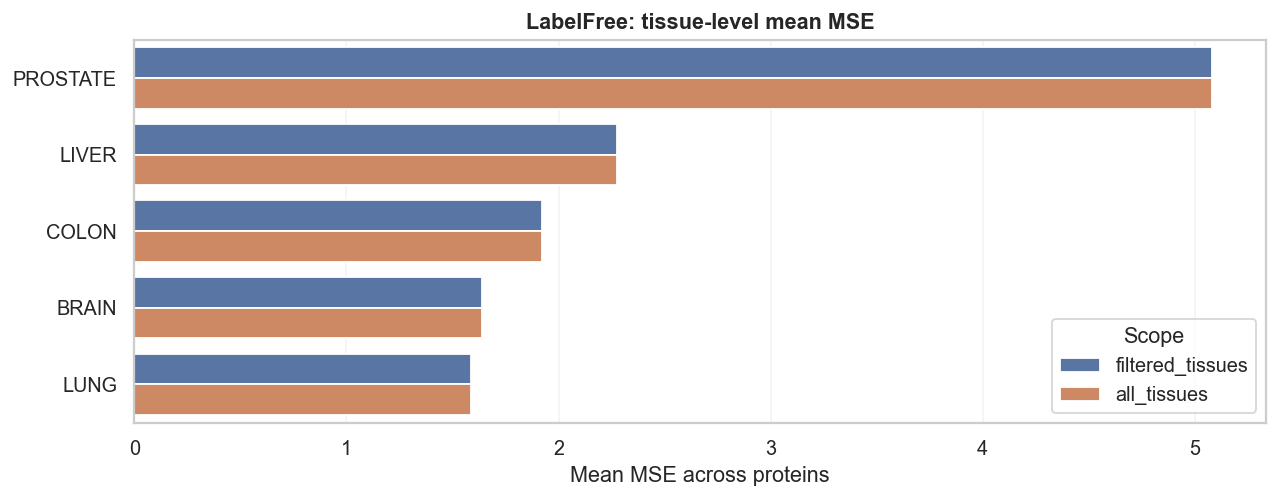

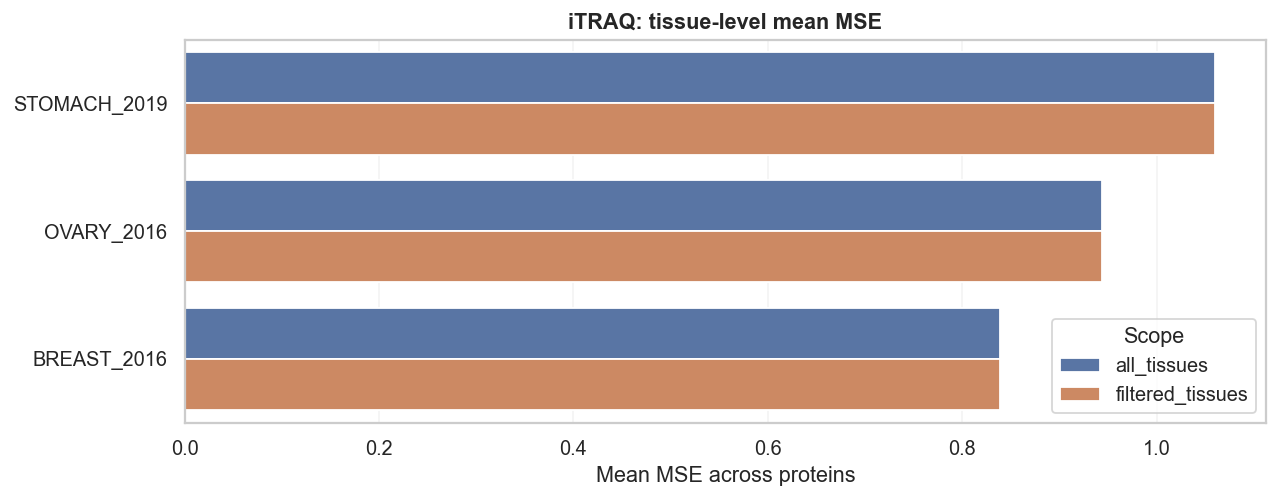

In [ ]:
tissue_rows = []
for (dataset, scope), bundle in cptac_results.items():
    tdf = bundle["tissue_df"].copy()
    if len(tdf):
        tissue_rows.append(tdf)

tissue_mse_df = pd.concat(tissue_rows, ignore_index=True) if tissue_rows else pd.DataFrame()
plot_cptac_tissue_mse(tissue_mse_df)

## 6. Top and bottom proteins

A concise table replaces the repeated per-dataset top-list cells from the original notebooks.

In [ ]:
if len(long_results_df):
    top_corr = (
        long_results_df.dropna(subset=["Correlation"])
        .sort_values(["Dataset", "Scope", "Correlation"], ascending=[True, True, False])
        .groupby(["Dataset", "Scope"], as_index=False)
        .head(10)
    )
    best_mse = (
        long_results_df.dropna(subset=["MSE"])
        .sort_values(["Dataset", "Scope", "MSE"], ascending=[True, True, True])
        .groupby(["Dataset", "Scope"], as_index=False)
        .head(10)
    )
    print("Top 10 proteins by correlation per dataset/scope")
    display(top_corr[["Dataset", "Scope", "Protein", "Correlation", "MSE", "Cosine_Similarity"]].round(4))
    print("Top 10 proteins by lowest MSE per dataset/scope")
    display(best_mse[["Dataset", "Scope", "Protein", "MSE", "Correlation", "Cosine_Similarity"]].round(4))

Top 10 proteins by correlation per dataset/scope


,Dataset,Scope,Protein,Correlation,MSE,Cosine_Similarity
379,LabelFree,all_tissues,AGR2,0.8171,5.8092,0.8408
463,LabelFree,all_tissues,KLC1,0.8081,0.3430,0.8068
471,LabelFree,all_tissues,MAP1B,0.7682,1.0933,0.7593
488,LabelFree,all_tissues,PEBP1,0.7508,0.1661,0.7515
404,LabelFree,all_tissues,COL12A1,0.7486,0.3916,0.7606
392,LabelFree,all_tissues,CAMK2G,0.7456,0.2820,0.7456
403,LabelFree,all_tissues,CNP,0.7390,0.6918,0.7310
548,LabelFree,all_tissues,TXNRD1,0.7195,0.3272,0.7205
412,LabelFree,all_tissues,COPS6,0.6975,1.5106,0.6932
380,LabelFree,all_tissues,AHSA1,0.6639,0.4847,0.6623


Top 10 proteins by lowest MSE per dataset/scope


,Dataset,Scope,Protein,MSE,Correlation,Cosine_Similarity
488,LabelFree,all_tissues,PEBP1,0.1661,0.7508,0.7515
394,LabelFree,all_tissues,CAV1,0.2297,0.6243,0.5973
494,LabelFree,all_tissues,PPA2,0.2786,0.5166,0.5097
392,LabelFree,all_tissues,CAMK2G,0.2820,0.7456,0.7456
548,LabelFree,all_tissues,TXNRD1,0.3272,0.7195,0.7205
375,LabelFree,all_tissues,ACSF2,0.3326,0.6400,0.6405
463,LabelFree,all_tissues,KLC1,0.3430,0.8081,0.8068
396,LabelFree,all_tissues,CDH1,0.3467,0.5370,0.6367
404,LabelFree,all_tissues,COL12A1,0.3916,0.7486,0.7606
497,LabelFree,all_tissues,PRDX3,0.3968,0.1776,0.1768


## 7. Optional exports

In [ ]:
SAVE_TABLES = False
if SAVE_TABLES:
    summary_df.to_csv(OUTPUT_DIR / "cptac_summary.csv", index=False)
    long_results_df.to_csv(OUTPUT_DIR / "cptac_protein_results.csv", index=False)
    tissue_mse_df.to_csv(OUTPUT_DIR / "cptac_tissue_mse.csv", index=False)
    coverage_df.to_csv(OUTPUT_DIR / "cptac_feature_coverage.csv", index=False)
    print("Saved tables to", OUTPUT_DIR.resolve())